<a href="https://colab.research.google.com/github/SadanandWatpalwad/DjangoAPI/blob/main/Major_Omkar_Bhosekar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Major Project - Cardio Training.csv to Major Project - Cardio Training.csv


In [3]:
import pandas as pd

file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name, sep=None, engine="python")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [4]:
import numpy as np

# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove patient ID because it is not a useful predictive feature
if "id" in df.columns:
    df = df.drop(columns=["id"])

# Convert age from days to years
df["age"] = df["age"] / 365.25

# Convert columns to numeric values
df = df.apply(pd.to_numeric, errors="coerce")

# Remove invalid target values
df = df.dropna(subset=["cardio"])
df = df[df["cardio"].isin([0, 1])]

# Remove clearly invalid blood pressure readings
df = df[
    (df["ap_hi"].between(70, 250)) &
    (df["ap_lo"].between(40, 200)) &
    (df["ap_hi"] >= df["ap_lo"])
]

# Check missing values
print("Missing values:\n", df.isnull().sum())
print("Cleaned dataset shape:", df.shape)

display(df.head())

Missing values:
 age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64
Cleaned dataset shape: (68673, 12)


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,50.357290,2,168,62.0,110,80,1,1,0,0,1,0
1,55.381246,1,156,85.0,140,90,3,1,0,0,1,1
2,51.627652,1,165,64.0,130,70,3,1,0,0,0,1
3,48.249144,2,169,82.0,150,100,1,1,0,0,1,1
4,47.841205,1,156,56.0,100,60,1,1,0,0,0,0


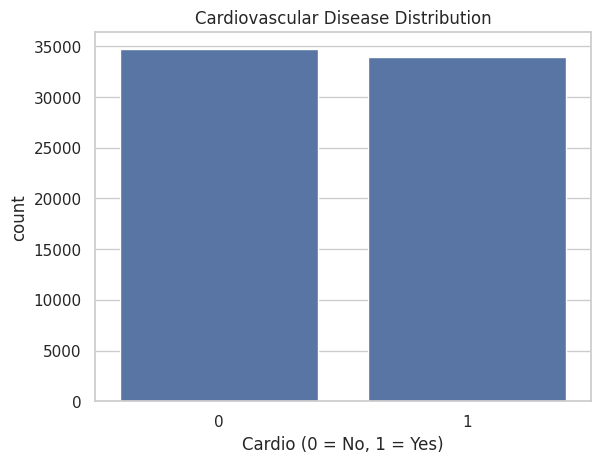

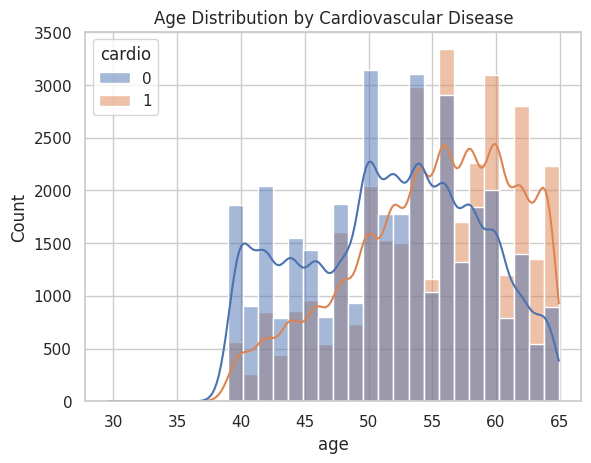

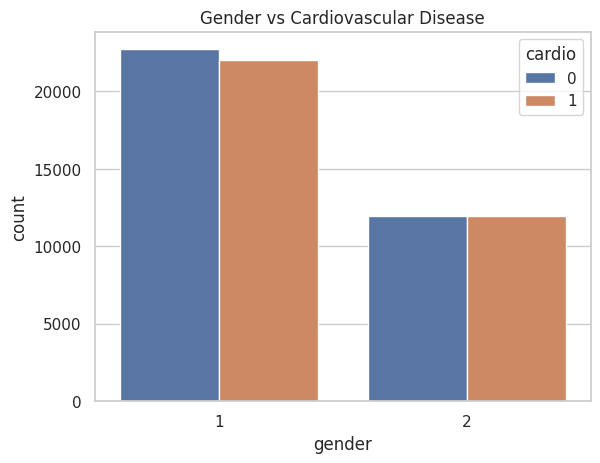

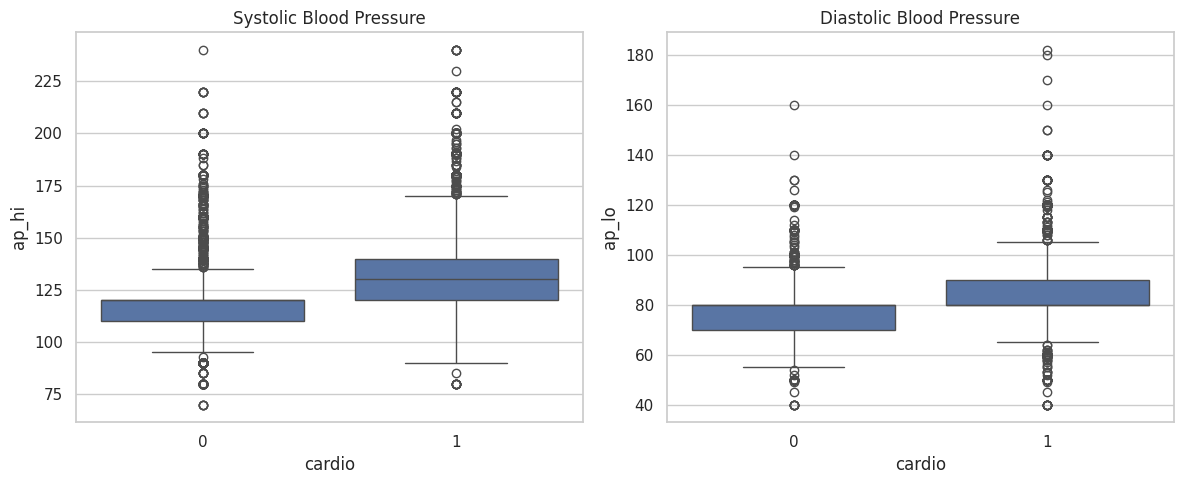

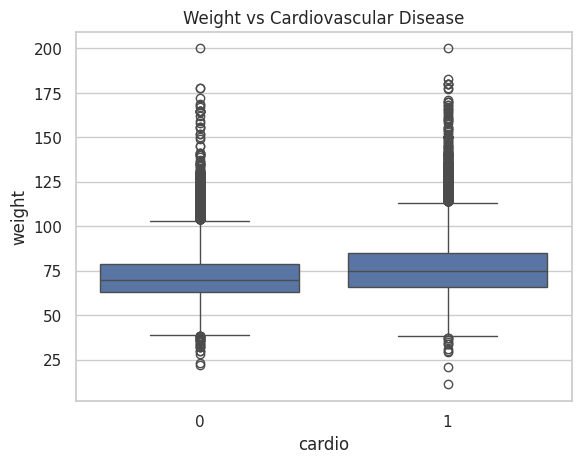

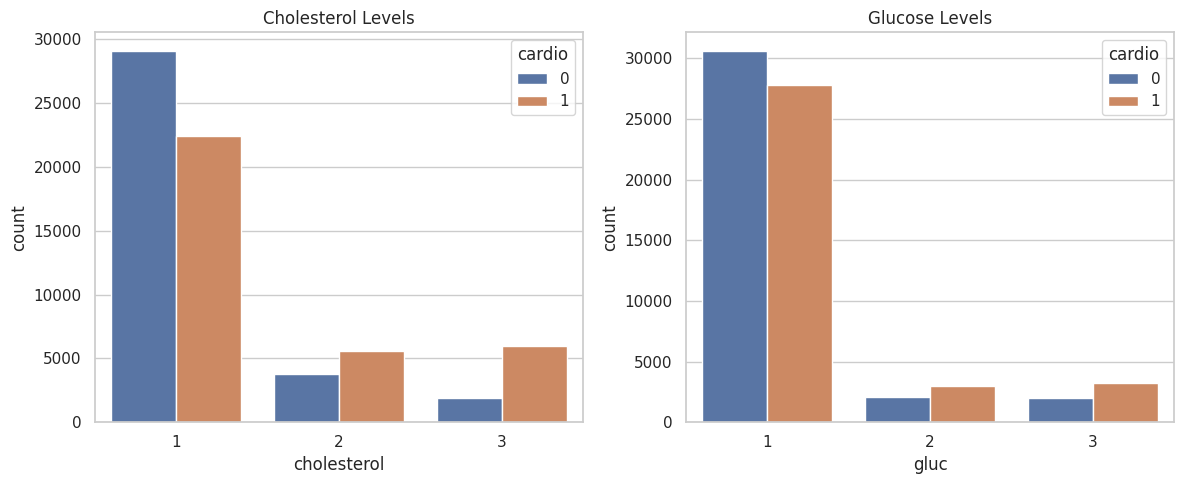

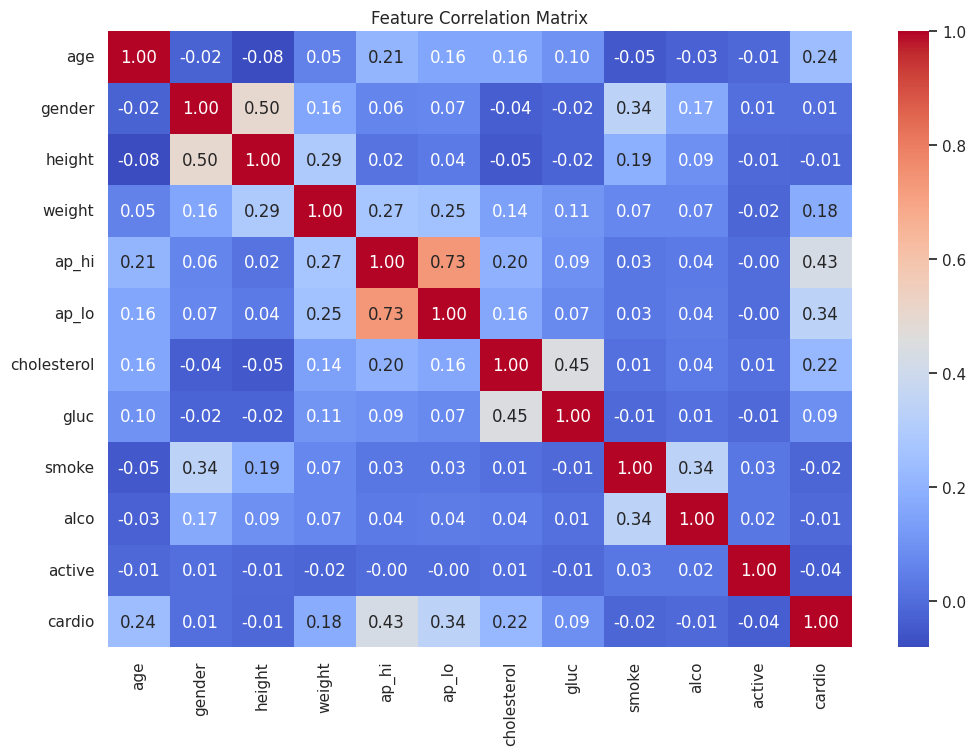

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Target distribution
sns.countplot(data=df, x="cardio")
plt.title("Cardiovascular Disease Distribution")
plt.xlabel("Cardio (0 = No, 1 = Yes)")
plt.show()

# 2. Age distribution
sns.histplot(data=df, x="age", hue="cardio",
             bins=30, kde=True)
plt.title("Age Distribution by Cardiovascular Disease")
plt.show()

# 3. Gender distribution
sns.countplot(data=df, x="gender", hue="cardio")
plt.title("Gender vs Cardiovascular Disease")
plt.show()

# 4. Blood pressure
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, x="cardio", y="ap_hi", ax=axes[0])
axes[0].set_title("Systolic Blood Pressure")
sns.boxplot(data=df, x="cardio", y="ap_lo", ax=axes[1])
axes[1].set_title("Diastolic Blood Pressure")
plt.tight_layout()
plt.show()

# 5. Weight distribution
sns.boxplot(data=df, x="cardio", y="weight")
plt.title("Weight vs Cardiovascular Disease")
plt.show()

# 6. Cholesterol and glucose
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(data=df, x="cholesterol", hue="cardio", ax=axes[0])
axes[0].set_title("Cholesterol Levels")
sns.countplot(data=df, x="gluc", hue="cardio", ax=axes[1])
axes[1].set_title("Glucose Levels")
plt.tight_layout()
plt.show()

# 7. Correlation matrix
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True,
            cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Separate features and target
X = df.drop(columns=["cardio"])
y = df["cardio"].astype(int)

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Define the models
models = {
    "SVM": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC()
    ),

    "KNN": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Decision Tree": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(random_state=42)
    ),

    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=100, random_state=42,
                               n_jobs=-1)
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print("Training:", name)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("Accuracy", ascending=False)

display(results_df.round(4))

Training: SVM
Training: KNN
Training: Decision Tree
Training: Logistic Regression
Training: Random Forest


,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.7249,0.7510,0.6643,0.7050
3,Logistic Regression,0.7188,0.7422,0.6614,0.6995
4,Random Forest,0.7070,0.7079,0.6942,0.7010
1,KNN,0.6883,0.6873,0.6787,0.6830
2,Decision Tree,0.6266,0.6205,0.6316,0.6260


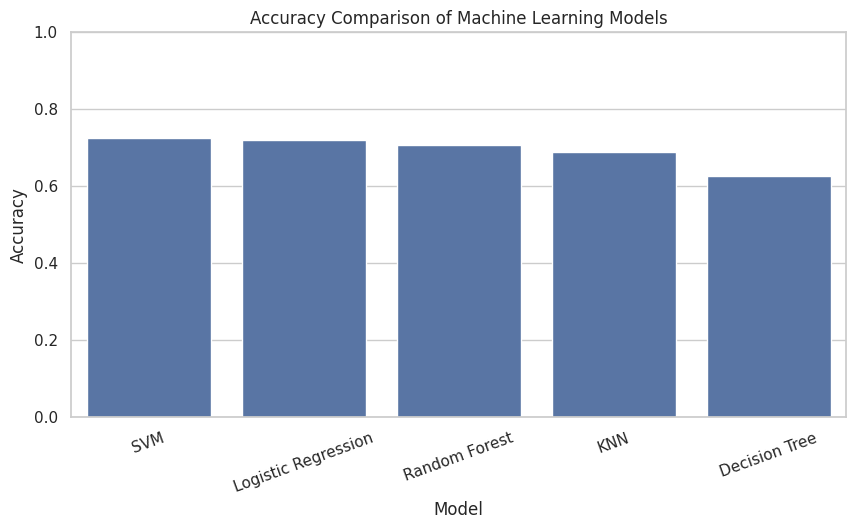

In [7]:
plt.figure(figsize=(10, 5))

sns.barplot(data=results_df, x="Model", y="Accuracy")

plt.title("Accuracy Comparison of Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

Best model: SVM

Classification Report:

              precision    recall  f1-score   support

           0       0.70      0.78      0.74      6940
           1       0.75      0.66      0.70      6795

    accuracy                           0.72     13735
   macro avg       0.73      0.72      0.72     13735
weighted avg       0.73      0.72      0.72     13735



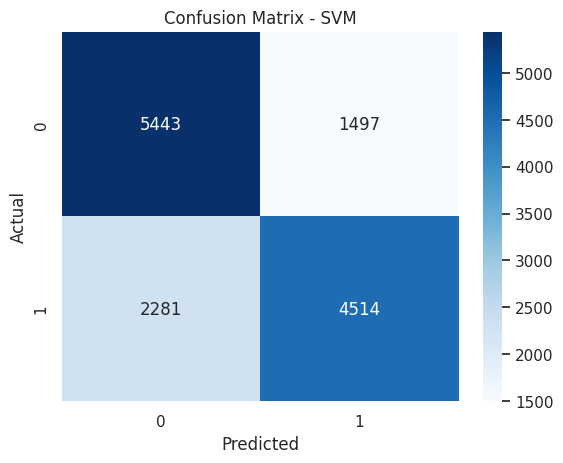

In [8]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

print("Best model:", best_model_name)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [9]:
import joblib

joblib.dump(best_model, "best_cardio_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [10]:
from google.colab import files

files.download("best_cardio_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>